# 02 — Data

This notebook describes the data every model in the project uses: where it comes from, how the two sources are joined, how we checked that the volatility labels can be trusted, and how each report's text becomes input for FinBERT.

**Running it.** Building the data takes hours (a 14 GB download is streamed, then FinBERT reads every report for about 11 hours on a laptop GPU), so this notebook does not repeat those steps. It loads their saved outputs from `data/processed/`. To rebuild them from scratch, run in order:

1. `Oscar/02-Merge-Kogan-EDGAR.ipynb`: downloads the Kogan corpus, streams EDGAR-CORPUS, joins them
2. `Oscar/03-Item7-Source.ipynb`: chooses which Item 7 text FinBERT reads
3. `python Oscar/extract_finbert.py`: FinBERT reads every report (saved in shards, resumable)
4. `python Oscar/build_dataset.py`: stacks the shards into `dataset.csv` and the embedding arrays
5. `Oscar/04-Volatility-Checking.ipynb`: label checks (also saves the text flags used in section 5)

Those notebooks hold the full working; this one summarises the decisions and the evidence for them.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("..")                       # this notebook lives in report/
PROCESSED = ROOT / "data" / "processed"  # made by the steps above (not committed)
OUTPUT = ROOT / "data" / "output"        # figures and tables for the report (committed)
OUTPUT.mkdir(parents=True, exist_ok=True)

merged = pd.read_csv(PROCESSED / "kogan_edgar_merged.csv", parse_dates=["date"])  # every Kogan report + match flags
df = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"])                # the reports the models use
flags = pd.read_csv(PROCESSED / "text_flags.csv")                                 # takeover / distress wording

def to_annual(logvol):
    # log of daily s.d. -> annualised volatility as a fraction (0.5 = 50% a year)
    return np.exp(logvol) * np.sqrt(252)

print(f"Kogan reports: {len(merged):,} | reports used by the models: {len(df):,}")

Kogan reports: 30,465 | reports used by the models: 27,142


## 1. Choosing the data

The question needs two things for each report: its **text**, and a measure of the company's **risk after the report was filed**. Text is easy to find, since every 10-K is public on the SEC's EDGAR system. The hard part is the risk label, which needs daily share prices for every company, *including those that later went bankrupt or were taken over*. Leaving those out would remove exactly the reports where risk changed most.

We chose the **10-K Corpus** of Kogan et al. (2009), which provides both:

- 10-K reports from 1996–2006, with Item 7 (MD&A) already extracted and tokenised
- for each report, the log volatility over the 12 months **before** filing (our baseline input) and the 12 months **after** (our target)
- the labels were computed from CRSP (the Center for Research in Security Prices), the standard academic price database, which keeps companies after they are delisted
- free, with no login, about 350 MB, and the paper's own scores give us a benchmark to reproduce

For **Item 1** (the business description) we add **EDGAR-CORPUS** (Loukas et al., 2021), which has every 10-K from 1993–2020 already split into its sections.

**Alternatives we rejected** (the full log is in [`data/README.md`](../data/README.md)):

| Source | Why not |
|---|---|
| EDGAR-CORPUS alone | Text only, no prices or labels. Used for Item 1 |
| Stocks-Yearly-Sections10K (Hugging Face) | Sections since 2001 with tickers, but a paid download and no prices |
| Yahoo Finance prices with our own labels | Mostly covers companies that still exist. In a 2004 test only 26% of reports could be labelled, and the ones lost were 23% more volatile (`Oscar/01-Planning.ipynb`) |
| Bloomberg Terminal | Access in person only; the data cannot go in a public repository |
| NCCU extended 10-K corpus (1996–2013) | Website unreachable (expired security certificate) |

The Yahoo test also served as an independent check on Kogan's labels. For the 917 reports where both exist, our recomputed volatility correlates 0.99 with Kogan's, and 91% agree within 10%.

## 2. Joining the two sources

Kogan decides which reports are in the study and supplies the labels. EDGAR-CORPUS supplies the section texts. The two are joined on the company's SEC number (CIK) and the filing year:

- **190 reports** share a company and year with another Kogan report, so they cannot be matched unambiguously, and we drop them.
- EDGAR-CORPUS is about 1.3 GB a year (14 GB in total). Rather than store it, we stream it line by line and keep only the reports that match, which brings it down to a few hundred MB.
- A report is **usable** if it has a label, a match, and an Item 1 of at least 100 words.
- **Same-company check:** the company's name from Kogan appears in the EDGAR text for 98.9% of the matched reports we could check. Inspecting the misses by hand shows mostly spelling differences ("Applebee's" against "APPLEBEES") rather than wrong matches.

kept 27,142 of 30,465 (89.1%); range 87.0–90.9% by year


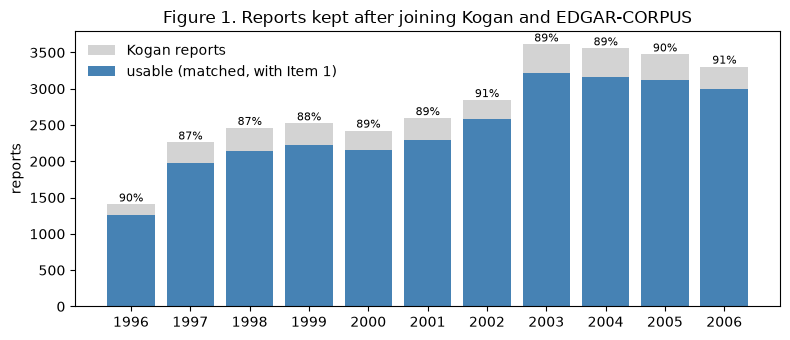

In [2]:
by_year = merged.groupby("year").agg(kogan=("key", "size"), usable=("usable", "sum"),
                                     has_item1A=("has_item1A", "mean"))
by_year["kept %"] = (100 * by_year["usable"] / by_year["kogan"]).round(1)
print(f"kept {by_year['usable'].sum():,} of {by_year['kogan'].sum():,} "
      f"({by_year['usable'].sum() / by_year['kogan'].sum():.1%}); "
      f"range {by_year['kept %'].min()}–{by_year['kept %'].max()}% by year")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_year.index, by_year["kogan"], color="lightgrey", label="Kogan reports")
ax.bar(by_year.index, by_year["usable"], color="steelblue", label="usable (matched, with Item 1)")
for y, row in by_year.iterrows():
    ax.text(y, row["kogan"] + 40, f"{row['kept %']:.0f}%", ha="center", fontsize=8)
ax.set_xticks(by_year.index)
ax.set_ylabel("reports")
ax.set_title("Figure 1. Reports kept after joining Kogan and EDGAR-CORPUS")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "fig1_reports_kept.png", dpi=150)

**Is what we lose different?** Dropping reports is only harmless if the dropped ones are not systematically more (or less) risky. We compare the next-year volatility of kept and lost reports with Welch's t-test:

In [3]:
def compare(flag):
    keep = merged.loc[merged[flag], "logvol_after"]
    lose = merged.loc[~merged[flag], "logvol_after"]
    return pd.Series({"kept": len(keep), "lost": len(lose),
                      "lost more volatile by %": 100 * (np.exp(lose.mean() - keep.mean()) - 1),
                      "p-value": stats.ttest_ind(keep, lose, equal_var=False).pvalue})

pd.DataFrame({"matched in EDGAR": compare("matched"), "usable": compare("usable")}).round(3)

,matched in EDGAR,usable
kept,28286.000,27142.000
lost,2179.000,3323.000
lost more volatile by %,3.645,-1.763
p-value,0.088,0.248


The lost reports are within 4% of the kept ones in volatility, and neither difference is significant at the 5% level. Year by year the gap changes sign with no pattern (see `Oscar/02-Merge-Kogan-EDGAR.ipynb`, section 6), which is what noise looks like. Compare the Yahoo route, which would have kept 26% of reports and lost the riskier ones. **We keep 27,142 of 30,465 reports (89%, and 87–91% in every year) without introducing a detectable bias.**

## 3. Which Item 7 should FinBERT read?

Item 7 exists in both sources, extracted by different software: a hand-written header-matching script in Kogan's case, and EDGAR-CORPUS's own parser. If both extractions were right they would be about the same length. Figure 2 compares them:

median EDGAR/Kogan length ratio 0.94; within 0.5–2x: 88%; EDGAR much shorter (<0.5x): 9.2%; much longer (>2x): 2.4%


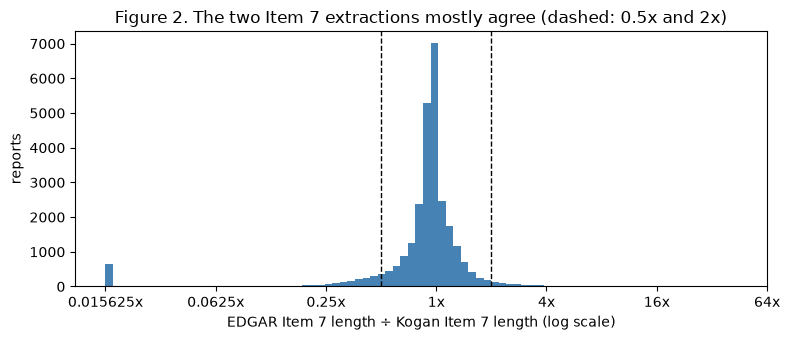

In [4]:
r = merged.loc[merged["matched"], "item7_ratio"]
print(f"median EDGAR/Kogan length ratio {r.median():.2f}; "
      f"within 0.5–2x: {r.between(0.5, 2).mean():.0%}; "
      f"EDGAR much shorter (<0.5x): {(r < 0.5).mean():.1%}; much longer (>2x): {(r > 2).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log2(r.clip(1 / 64, 64)), bins=80, color="steelblue")
for edge in [0.5, 2]:
    ax.axvline(np.log2(edge), color="black", ls="--", lw=1)
ax.set_xticks(range(-6, 7, 2), [f"{2.0**k:g}x" for k in range(-6, 7, 2)])
ax.set_xlabel("EDGAR Item 7 length ÷ Kogan Item 7 length (log scale)")
ax.set_ylabel("reports")
ax.set_title("Figure 2. The two Item 7 extractions mostly agree (dashed: 0.5x and 2x)")
fig.tight_layout()
fig.savefig(OUTPUT / "fig2_item7_ratio.png", dpi=150)

The lengths agree for most reports. Reading the disagreements by eye (`Oscar/03-Item7-Source.ipynb`) shows three ways an extraction goes wrong:

| What goes wrong | Example | Which source is right |
|---|---|---|
| Kogan stops early at a cross-reference ("...as discussed in note # of") | Newmont Gold (1997), Woodward Governor (2006) | EDGAR |
| EDGAR runs past the end of Item 7 into the exhibit list | Blockbuster (2002) | Kogan |
| The company leaves Item 7 to its *Annual Report to Shareholders* ("incorporated by reference"), so EDGAR's section is a few lines long | Northeast Utilities (2005) | Kogan, which found the text in the exhibit |

Kogan et al. (2009) note the same "by reference" problem. To see how common each failure is, we searched every text for two markers: an auditor's report (a sign the text has run into Item 8) and by-reference wording. Of the 727 reports where EDGAR's Item 7 is nearly empty, 31% use by-reference wording, against about 2% of normal reports. Neither marker explains the more common moderate disagreements, which mostly come from Kogan's text including Item 7A.

**Rule:** FinBERT reads EDGAR's Item 7, which is clean prose with headings, like the text FinBERT was trained on, and comes from the same parser as Item 1. When EDGAR's Item 7 has under 100 words, FinBERT reads Kogan's instead. The 100-word threshold is a simple rule rather than a tuned one. Our reproduction of Kogan's word-count models uses Kogan's own text, so that comparison is like for like.

In [5]:
df["item7_source"].value_counts().to_frame("reports").assign(share=lambda t: (t["reports"] / len(df)).map("{:.1%}".format))

,reports,share
item7_source,,
edgar,26538,97.8%
kogan,604,2.2%


## 4. The volatility labels

Kogan et al. define volatility as the standard deviation of a stock's daily returns over 12 months, and every model predicts its natural log:

$$\text{logvol} = \log\big(\operatorname{sd}(r_1, \dots, r_T)\big), \qquad r_t = \log\frac{p_t}{p_{t-1}},$$

where $p_t$ is the closing price on trading day $t$. Logs are used because volatility is strongly right-skewed while log volatility is roughly bell-shaped, and because MSE on logs penalises a doubling and a halving equally. To read a value, $\exp(\text{logvol})\sqrt{252}$ is the annualised volatility (252 trading days a year).

**Checks** (details in `Oscar/04-Volatility-Checking.ipynb`):

- **Complete:** every report has a before label, an after label and a metadata line. Nine reports are listed twice in the raw files, always with identical values.
- **Carried through correctly:** the labels in `dataset.csv` equal the raw files for 100% of reports, and every filing date matches the date in the report's key.
- **No placeholders:** no missing or infinite values, and no value occurs more than three times.
- **Independent:** recomputed from Yahoo prices for 2004, correlation 0.99 (section 1).

In [6]:
sp = pd.read_pickle(PROCESSED / "sp500_prices.pkl")      # S&P 500 index, daily closes from Yahoo (^GSPC)
sp_ret = np.log(sp).diff().dropna()

def index_logvol(filed):
    # same formula as Kogan's labels, applied to the index over the 12 months after `filed`
    w = sp_ret[(sp_ret.index > filed) & (sp_ret.index <= filed + pd.DateOffset(years=1))]
    return np.log(w.std())

df["index_logvol_after"] = df["date"].map(index_logvol)

for col in ["logvol_before", "logvol_after"]:
    print(f"{col}: median {to_annual(df[col].median()):.0%} a year, "
          f"middle 90% {to_annual(df[col].quantile(0.05)):.0%}–{to_annual(df[col].quantile(0.95)):.0%}")
print(f"S&P 500 over the same 12 months after filing: median {to_annual(df['index_logvol_after'].median()):.0%} a year")
print(f"correlation of before and after: {df['logvol_before'].corr(df['logvol_after']):.2f}")

logvol_before: median 53% a year, middle 90% 20%–135%
logvol_after: median 50% a year, middle 90% 19%–144%
S&P 500 over the same 12 months after filing: median 17% a year
correlation of before and after: 0.83


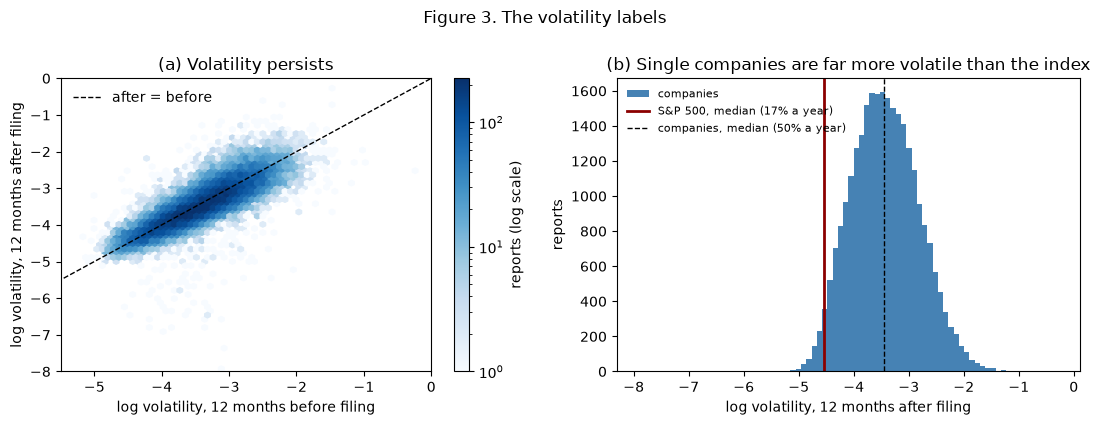

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
hb = ax.hexbin(df["logvol_before"], df["logvol_after"], gridsize=60, bins="log", cmap="Blues", mincnt=1)
lims = [-8, 0]
ax.plot(lims, lims, color="black", lw=1, ls="--", label="after = before")
ax.set_xlim(-5.5, 0); ax.set_ylim(*lims)
ax.set_xlabel("log volatility, 12 months before filing")
ax.set_ylabel("log volatility, 12 months after filing")
ax.set_title("(a) Volatility persists")
ax.legend(loc="upper left", frameon=False)
fig.colorbar(hb, ax=ax, label="reports (log scale)")

ax = axes[1]
ax.hist(df["logvol_after"], bins=80, color="steelblue", label="companies")
ax.axvline(df["index_logvol_after"].median(), color="darkred", lw=2,
           label=f"S&P 500, median ({to_annual(df['index_logvol_after'].median()):.0%} a year)")
ax.axvline(df["logvol_after"].median(), color="black", lw=1, ls="--",
           label=f"companies, median ({to_annual(df['logvol_after'].median()):.0%} a year)")
ax.set_xlabel("log volatility, 12 months after filing")
ax.set_ylabel("reports")
ax.set_title("(b) Single companies are far more volatile than the index")
ax.legend(loc="upper left", frameon=False, fontsize=8)

fig.suptitle("Figure 3. The volatility labels", y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT / "fig3_labels.png", dpi=150, bbox_inches="tight")

Figure 3(a) shows why last year's volatility is such a strong baseline: the points lie close to the diagonal. Figure 3(b) is a sense check. A typical company is about three times as volatile as the S&P 500, as expected, because a single firm's own news does not average out across hundreds of others (Campbell et al., 2001).

## 5. The extreme labels are real events

Both tails of Figure 3(b) stretch a long way. Before trusting the labels we looked at every extreme report individually, with two thresholds:

- **very low:** log volatility below −5, under about 11% a year, calmer than the whole market in most years
- **very high:** log volatility above −1.5, over about 350% a year, where the price regularly moves 20% in a day

We flag each report's text for takeover wording ("agreement and plan of merger", "tender offer", ...) and distress wording ("going concern", "Chapter 11", "bankruptcy", "delist"), and check whether the company filed another 10-K the following year.

In [8]:
ext = df.merge(flags, on=["cik", "year"], how="left")
ext["group"] = np.select([ext["logvol_after"] < -5, ext["logvol_after"] > -1.5], ["very low", "very high"], "ordinary")

summary = ext.groupby("group").agg(
    reports=("key", "size"),
    median_vol_before=("logvol_before", lambda v: f"{to_annual(v.median()):.0%}"),
    median_vol_after=("logvol_after", lambda v: f"{to_annual(v.median()):.0%}"),
    takeover_wording=("takeover", lambda v: f"{v.mean():.0%}"),
    distress_wording=("distress", lambda v: f"{v.mean():.0%}"),
    filed_next_year=("files_next_year", lambda v: f"{v.dropna().astype(bool).mean():.0%}"),   # 2006 filings excluded
).loc[["very low", "ordinary", "very high"]]
summary

,reports,median_vol_before,median_vol_after,takeover_wording,distress_wording,filed_next_year
group,,,,,,
very low,70,39%,6%,69%,29%,4%
ordinary,27034,53%,50%,17%,31%,78%
very high,38,158%,424%,24%,82%,13%


The two tails are two different kinds of event, and in both cases **the report itself says so**:

- **Very low = takeovers.** Once a company agrees to be bought for a fixed cash price, its shares trade just below that price until the deal closes, so measured volatility collapses. The company is not safe; it is about to disappear. Most of these reports describe the company's own sale (DEKALB to Monsanto, Odwalla to Coca-Cola, Inktomi to Yahoo!), and almost none file again. Their volatility *before* filing was ordinary, so the "copy last year" baseline misses them badly.
- **Very high = distress.** Most contain going-concern warnings from the auditors or describe a Chapter 11 filing (Salon Media, Iwerks, eMagin). They cluster in the 1998–2002 dot-com boom and crash. Unlike the takeovers, they were already very volatile, so the baseline partly anticipates them.

These are genuine prices, not data errors, so **we keep them**. They are also where text has the clearest chance to beat the baseline. Squared error weights them heavily: the 70 very-low reports (0.26% of the data) carry 10% of the baseline's total squared error. We will report results with and without them so that a handful of takeovers cannot drive the conclusions.

In [9]:
low = df["logvol_after"] < -5
sq_err = (df["logvol_after"] - df["logvol_before"]) ** 2      # error of "copy last year"
print(f"very-low reports: {low.sum()} ({low.mean():.2%}) carry {sq_err[low].sum() / sq_err.sum():.1%} of the baseline's squared error")
print(f"baseline MSE: all reports {sq_err.mean():.3f}, without them {sq_err[~low].mean():.3f}")

very-low reports: 70 (0.26%) carry 10.0% of the baseline's squared error
baseline MSE: all reports 0.128, without them 0.116


## 6. From text to FinBERT input

FinBERT reads at most 512 tokens at a time. For each report and each section (Item 1 and Item 7, kept separate):

1. the text is split into FinBERT's own word-piece tokens;
2. the tokens are cut into consecutive **chunks of 510** (two slots are reserved for FinBERT's start and end markers);
3. at most **64 chunks** per section are kept (the true number is recorded);
4. each chunk is passed through FinBERT, and we keep its **CLS vector**, the 768 numbers FinBERT uses to summarise the whole chunk, saved at half precision (float16) to halve the storage.

The output is one row per chunk in `item1_emb.npy` and `item7_emb.npy`, and `dataset.csv` records where each report's rows start. Reading the arrays memory-mapped means a model loads only the rows it needs.

In [10]:
rows = []
for s, name in [("item1", "Item 1"), ("item7", "Item 7")]:
    rows.append({"section": name,
                 "median chunks": df[f"{s}_true"].median(),
                 "90th percentile": df[f"{s}_true"].quantile(0.9),
                 "reports cut at 64": f"{(df[s + '_true'] > df[s + '_n']).mean():.2%}",
                 "chunks stored": f"{df[s + '_n'].sum():,}"})
pd.DataFrame(rows).set_index("section")

,median chunks,90th percentile,reports cut at 64,chunks stored
section,,,,
Item 1,14.0,31.0,0.27%,"444,394"
Item 7,16.0,33.0,0.57%,"498,607"


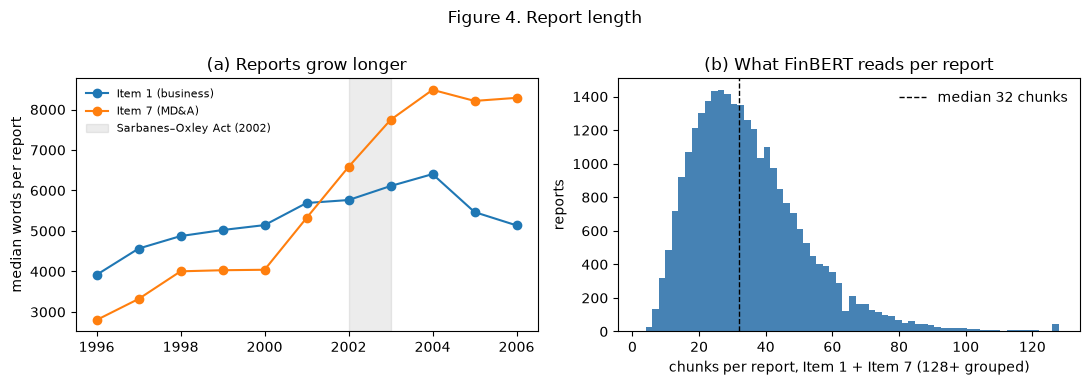

In [11]:
words = merged[merged["usable"]].groupby("year")[["edgar_item1_words", "edgar_item7_words"]].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(words.index, words["edgar_item1_words"], marker="o", label="Item 1 (business)")
ax.plot(words.index, words["edgar_item7_words"], marker="o", label="Item 7 (MD&A)")
ax.axvspan(2002, 2003, color="grey", alpha=0.15, label="Sarbanes–Oxley Act (2002)")
ax.set_ylabel("median words per report")
ax.set_title("(a) Reports grow longer")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
total = df["item1_true"] + df["item7_true"]
ax.hist(total.clip(upper=128), bins=64, color="steelblue")
ax.axvline(total.median(), color="black", ls="--", lw=1, label=f"median {total.median():.0f} chunks")
ax.set_xlabel("chunks per report, Item 1 + Item 7 (128+ grouped)")
ax.set_ylabel("reports")
ax.set_title("(b) What FinBERT reads per report")
ax.legend(frameon=False)

fig.suptitle("Figure 4. Report length", y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT / "fig4_length.png", dpi=150, bbox_inches="tight")

Fewer than 1% of reports are cut at 64 chunks, so the cap loses very little text. Item 7 roughly doubles in length over the decade, with the steepest rise around the Sarbanes–Oxley Act of 2002, which tightened reporting standards (Kogan et al. note the same jump). Item 1 grows until 2004 and then shrinks, probably because the risk discussion that companies used to put in their business description moved into the new Item 1A from 2005 (section 8). Both changes matter for modelling: a model trained on earlier years is tested on reports that are longer and organised differently, and length itself may carry information (Li, 2008).

## 7. Training and test years

Volatility moves with the market as a whole: it was high around the 2000–2002 crash and low by 2005. A random split would let a model learn each year's market mood from that year's own reports. We therefore split **by year**, as Kogan et al. did. Every model is tested on one year at a time and trained only on earlier years, so we can compare with their published scores for 2001–2006.

There is one subtlety. A report filed in, say, December 2005 has a label covering December 2005 to December 2006, which **overlaps the 2006 test year**. Training on it leaks a little information about 2006's market. So we use two training windows:

- **Paper:** the five years before the test year (Kogan et al., 2009), for direct comparison
- **Strict:** the four years ending two years before the test year, so no training label overlaps the test period

In [12]:
split_rows = []
for test in range(2001, 2007):
    for window, years in [("paper", range(test - 5, test)), ("strict", range(test - 5, test - 1))]:
        split_rows.append({"test_year": test, "window": window,
                           "train_years": f"{min(years)}–{max(years)}",
                           "train_reports": int(df["year"].isin(years).sum()),
                           "test_reports": int((df["year"] == test).sum())})
splits = pd.DataFrame(split_rows)
splits.to_csv(OUTPUT / "splits.csv", index=False)     # every model notebook reads its splits from here
splits.set_index(["test_year", "window"])

train_years  train_reports  test_reports
test_year window                                         
2001      paper    1996–2000           9747          2299
          strict   1996–1999           7596          2299
2002      paper    1997–2001          10788          2587
          strict   1997–2000           8489          2587
2003      paper    1998–2002          11399          3217
          strict   1998–2001           8812          3217
2004      paper    1999–2003          12474          3168
          strict   1999–2002           9257          3168
2005      paper    2000–2004          13422          3121
          strict   2000–2003          10254          3121
2006      paper    2001–2005          14392          3003
          strict   2001–2004          11271          3003

Model notebooks read their splits from `data/output/splits.csv`, so every model is scored on exactly the same reports. *Proposed, to agree as a group:* hyperparameters are tuned on the last training year (a validation year), never on the test year.

## 8. Limitations, and how this compares with real-world data

- **Age.** The reports are from 1996–2006. Today's 10-Ks are longer, and markets, reporting rules and language have changed, so a model trained here would need retraining before use.
- **No Risk Factors section.** Item 1A, where companies now list their main risks, only became mandatory for fiscal years ending after 1 December 2005 (SEC, 2005). It is in under 1% of our reports up to 2004, then 64% in 2005 and 90% in 2006, so it exists only in the last test years and never across a full training window. We leave it out of the main study; a modern version would almost certainly include it.
- **Delisted companies.** Kogan's corpus contains only reports with a complete label, so companies delisted soon after filing are missing. Delisting is concentrated among failing firms (Shumway, 1997), so the riskiest tail is somewhat under-represented, even though CRSP keeps those firms.
- **Labels we cannot rebuild.** CRSP needs a subscription we do not have. We rely on Kogan's labels and have checked them against Yahoo (correlation 0.99) where possible.
- **Extraction errors.** Section boundaries are found by software, and section 3 shows that both extractors make mistakes. Our rule removes the worst cases (empty sections) but not every imperfect one.

**Compared with a real deployment**, an investor or regulator would score every new 10-K as it is filed, using all sections including Risk Factors. They would face the same long-document problem at a far larger volume across all filing types, which is the setting of our scale argument.

## Summary

| | |
|---|---|
| Reports | 27,142 10-Ks, 1996–2006 (89% of the Kogan corpus), with no detectable selection bias |
| Target | log volatility over the 12 months after filing (CRSP, via Kogan et al.) |
| Baseline input | log volatility over the 12 months before filing |
| Text | Item 1 and Item 7, from EDGAR-CORPUS (Item 7 from Kogan for 2.2% of reports) |
| Model input | FinBERT CLS vectors, 768 numbers per 510-token chunk, median 32 chunks per report |
| Split | by year; test 2001–2006; "paper" and "strict" training windows |

## References

- Campbell, J. Y., Lettau, M., Malkiel, B. G. & Xu, Y. (2001). Have individual stocks become more volatile? An empirical exploration of idiosyncratic risk. *Journal of Finance*, 56(1), 1–43.
- Center for Research in Security Prices (CRSP). *US Stock Databases*. University of Chicago Booth School of Business. (Source of Kogan et al.'s labels.)
- Kogan, S., Levin, D., Routledge, B. R., Sagi, J. S. & Smith, N. A. (2009). Predicting risk from financial reports with regression. *NAACL-HLT 2009*, 272–280. Data: https://www.cs.cmu.edu/~ark/10K/
- Li, F. (2008). Annual report readability, current earnings, and earnings persistence. *Journal of Accounting and Economics*, 45(2–3), 221–247.
- Loukas, L., Fergadiotis, M., Androutsopoulos, I. & Malakasiotis, P. (2021). EDGAR-CORPUS: Billions of tokens make the world go round. *Third Workshop on Economics and Natural Language Processing (ECONLP)*. https://aclanthology.org/2021.econlp-1.2
- Securities and Exchange Commission (2005). *Securities Offering Reform*. Release No. 33-8591.
- Shumway, T. (1997). The delisting bias in CRSP data. *Journal of Finance*, 52(1), 327–340.
- Yahoo Finance, daily prices via the `yfinance` package (S&P 500 index `^GSPC`; 2004 label check).